In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
from sklearn.datasets import fetch_openml
mnist = fetch_openml("mnist_784",version=1)
mnist.keys()

dict_keys(['data', 'target', 'frame', 'categories', 'feature_names', 'target_names', 'DESCR', 'details', 'url'])

In [4]:
mnist['data']

,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
69996,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
69997,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
69998,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:
x=mnist['data']
y=mnist['target']



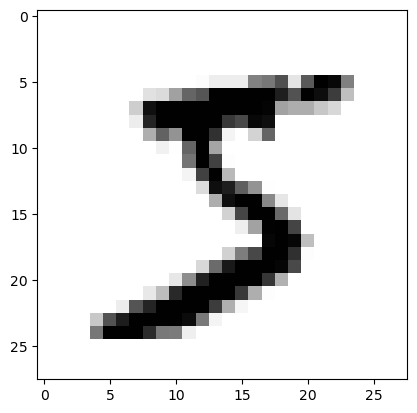

In [9]:
dig = pd.DataFrame(x.iloc[0,:])
some_number=dig
dig = dig.to_numpy().reshape(28,28)
plt.imshow(dig,cmap='binary')
plt.show()

In [6]:
y=y.astype(np.int16)

In [7]:
#Since the dataset is already sampled to be split at 60000
x_train,x_test,y_train,y_test = x[:60000],x[60000:],y[:60000],y[60000:]
print(x_train.shape,y_train.shape)

(60000, 784) (60000,)


In [8]:
y_train_5 = (y_train==5)
y_test_5 = (y_test==5)

In [9]:
print(x_train.iloc[0,:])

pixel1      0
pixel2      0
pixel3      0
pixel4      0
pixel5      0
           ..
pixel780    0
pixel781    0
pixel782    0
pixel783    0
pixel784    0
Name: 0, Length: 784, dtype: int64


In [10]:
from sklearn.linear_model import SGDClassifier
model =SGDClassifier(random_state=42)
model.fit(x_train,y_train_5)

SGDClassifier(random_state=42)

In [11]:
some_number

,0
pixel1,0
pixel2,0
pixel3,0
pixel4,0
pixel5,0
...,...
pixel780,0
pixel781,0
pixel782,0
pixel783,0


In [12]:
some_number=some_number.T

In [13]:
model.predict(some_number)


array([ True])

In [14]:
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone

skfold = StratifiedKFold(n_splits=3)
for train_index,test_index in skfold.split(x_train,y_train_5):
    xtrain_fold = x_train.iloc[train_index]
    ytrain_fold = y_train_5.iloc[train_index]

    xtest_fold = x_train.iloc[test_index]
    ytest_fold = y_train_5.iloc[test_index]

    clm = clone(model)
    clm.fit(xtrain_fold,ytrain_fold)
    y_pred = clm.predict(xtest_fold)
    acc = sum(y_pred == ytest_fold)/len(y_pred)
    print(acc)
print(y)


0.95035
0.96035
0.9604
0        5
1        0
2        4
3        1
4        9
        ..
69995    2
69996    3
69997    4
69998    5
69999    6
Name: class, Length: 70000, dtype: int16


In [15]:
from sklearn.model_selection import cross_val_score
cross_val_score(model,x_test,y_test_5,cv=5,scoring='accuracy')

array([0.9575, 0.95  , 0.9645, 0.963 , 0.972 ])

In [16]:
from sklearn.model_selection import cross_val_predict
yhat = cross_val_predict(model,x_test,y_test_5,cv=5)

In [17]:
from sklearn.metrics import confusion_matrix
print(confusion_matrix(y_test_5,yhat))

[[8919  189]
 [ 197  695]]


In [18]:
y_score=model.decision_function(some_number)
print(y_score)

[2164.22030239]


In [43]:
y_scores=cross_val_predict(model,x_test,y_test_5,cv=3,method='decision_function')
y_scores

array([-445817.45627918, -122573.29461554, -301377.7182004 , ...,
       -177938.90726622,   43350.96795041, -346162.83091422],
      shape=(10000,))

In [44]:
from sklearn.metrics import precision_recall_curve
precision,rrecall,thresholds = precision_recall_curve(y_test_5,y_scores)


In [45]:
print(len(thresholds))


10000


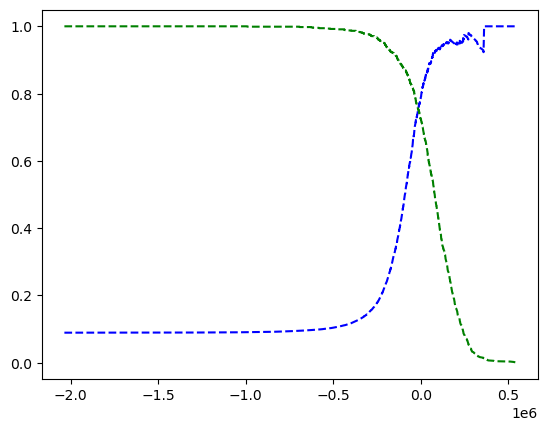

In [46]:
def plot_precision_recall(prec,recall,thresh):
    plt.plot(thresh,prec[:-1],'b--',label='precision')
    plt.plot(thresh,recall[:-1],"g--",label='recall')
    plt.show()
plot_precision_recall(precision,rrecall,thresholds)


In [47]:
from sklearn.metrics import roc_curve
fpr,tpr,thresholds = roc_curve(y_test_5,y_scores)

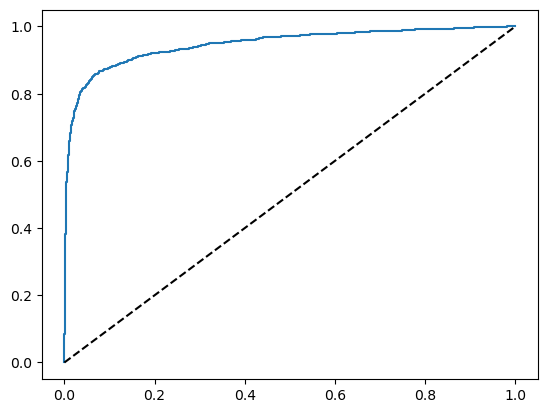

In [48]:
def plot_roc_curve(fpr,tpr):
    plt.plot(fpr,tpr)
    plt.plot([0,1],[0,1],'k--')
    plt.show()

plot_roc_curve(fpr,tpr)


In [49]:
from sklearn.metrics import roc_auc_score
print(roc_auc_score(y_test_5,y_scores))

0.9471299562204222


In [52]:
from sklearn.ensemble import RandomForestClassifier
rfc = RandomForestClassifier(random_state=42)
rfc.fit(x_train,y_train_5)
y_probas_forest = cross_val_predict(rfc,x_test,y_test_5,cv=3,method='predict_proba')

[]

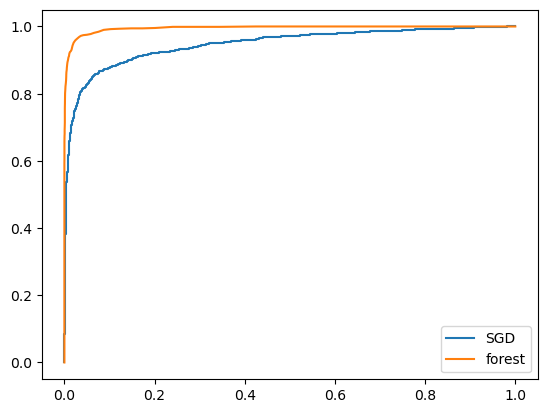

In [53]:
y_forest_score = y_probas_forest[:,1]
fpr_forest,tpr_forest,thresholds_forest = roc_curve(y_test_5,y_forest_score)
plt.plot(fpr,tpr,label='SGD')
plt.plot(fpr_forest,tpr_forest,label='forest')
plt.legend(loc='lower right')
plt.plot()

In [ ]:
from sklearn.svm import SVC
svc = SVC()
svc.fit(x_train,y_train)


d:\Anaconda\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


ValueError: Found array with dim 3. SVC expected <= 2.

In [56]:
svc.predict(some_number)

array([5], dtype=int16)

In [58]:
svc.decision_function(some_number)

array([[ 1.72501977,  2.72809088,  7.2510018 ,  8.3076379 , -0.31087254,
         9.3132482 ,  1.70975103,  2.76765202,  6.23049537,  4.84771048]])

In [ ]:
from sklearn.multiclass import OneVsRestClassifier
rsvc=OneVsRestClassifier(SVC())
rsvc.fit(x_train,y_train)


In [ ]:
cross_val_score(svc,x_test,y_test,cv=3)


array([0.93491302, 0.95229523, 0.96669667])

In [61]:
from sklearn.preprocessing import StandardScaler
x_train_scaled = StandardScaler().fit_transform(x_train) 

In [62]:
y_train_pred = cross_val_predict(svc,x_train,y_train,cv=3)
print(y_train.shape,y_train_pred.shape)

(60000,) (60000,)


In [63]:
mat = confusion_matrix(y_train,y_train_pred)
mat

array([[5863,    3,   10,    2,    4,    8,   14,    2,   13,    4],
       [   1, 6664,   26,    9,   10,    1,    3,   10,   10,    8],
       [  19,    9, 5811,   16,   26,    5,    8,   30,   28,    6],
       [   3,    9,   54, 5891,    2,   62,    1,   30,   61,   18],
       [   5,   11,   13,    0, 5712,    0,   20,    9,    4,   68],
       [  11,    6,   10,   57,   14, 5255,   35,    4,   17,   12],
       [  20,    8,    7,    0,   10,   32, 5831,    0,   10,    0],
       [   5,   21,   42,    6,   35,    2,    1, 6100,    7,   46],
       [   8,   29,   19,   38,   20,   39,   21,    9, 5646,   22],
       [  14,   11,    4,   31,   72,   16,    2,   59,   19, 5721]])

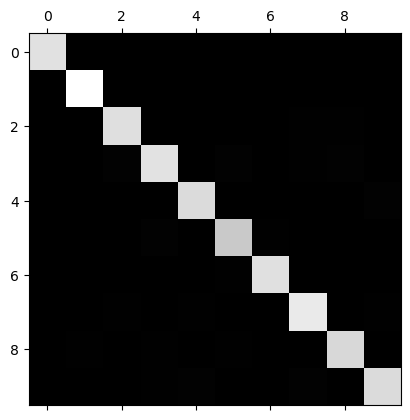

In [65]:
plt.matshow(mat,cmap=plt.cm.gray)

In [66]:
rowsum = mat.sum(axis=1,keepdims=True)
normat = mat/rowsum
normat

array([[9.89869998e-01, 5.06500084e-04, 1.68833361e-03, 3.37666723e-04,
        6.75333446e-04, 1.35066689e-03, 2.36366706e-03, 3.37666723e-04,
        2.19483370e-03, 6.75333446e-04],
       [1.48323939e-04, 9.88430733e-01, 3.85642243e-03, 1.33491546e-03,
        1.48323939e-03, 1.48323939e-04, 4.44971818e-04, 1.48323939e-03,
        1.48323939e-03, 1.18659152e-03],
       [3.18898959e-03, 1.51057402e-03, 9.75327291e-01, 2.68546492e-03,
        4.36388050e-03, 8.39207788e-04, 1.34273246e-03, 5.03524673e-03,
        4.69956361e-03, 1.00704935e-03],
       [4.89316588e-04, 1.46794976e-03, 8.80769858e-03, 9.60854673e-01,
        3.26211059e-04, 1.01125428e-02, 1.63105529e-04, 4.89316588e-03,
        9.94943729e-03, 2.93589953e-03],
       [8.55871277e-04, 1.88291681e-03, 2.22526532e-03, 0.00000000e+00,
        9.77747347e-01, 0.00000000e+00, 3.42348511e-03, 1.54056830e-03,
        6.84697022e-04, 1.16398494e-02],
       [2.02914591e-03, 1.10680686e-03, 1.84467810e-03, 1.05146652e-02,
   

In [68]:
np.fill_diagonal(normat,0)
normat

array([[0.        , 0.0005065 , 0.00168833, 0.00033767, 0.00067533,
        0.00135067, 0.00236367, 0.00033767, 0.00219483, 0.00067533],
       [0.00014832, 0.        , 0.00385642, 0.00133492, 0.00148324,
        0.00014832, 0.00044497, 0.00148324, 0.00148324, 0.00118659],
       [0.00318899, 0.00151057, 0.        , 0.00268546, 0.00436388,
        0.00083921, 0.00134273, 0.00503525, 0.00469956, 0.00100705],
       [0.00048932, 0.00146795, 0.0088077 , 0.        , 0.00032621,
        0.01011254, 0.00016311, 0.00489317, 0.00994944, 0.0029359 ],
       [0.00085587, 0.00188292, 0.00222527, 0.        , 0.        ,
        0.        , 0.00342349, 0.00154057, 0.0006847 , 0.01163985],
       [0.00202915, 0.00110681, 0.00184468, 0.01051467, 0.00258255,
        0.        , 0.00645637, 0.00073787, 0.00313595, 0.00221361],
       [0.00337952, 0.00135181, 0.00118283, 0.        , 0.00168976,
        0.00540723, 0.        , 0.        , 0.00168976, 0.        ],
       [0.00079808, 0.00335196, 0.0067039

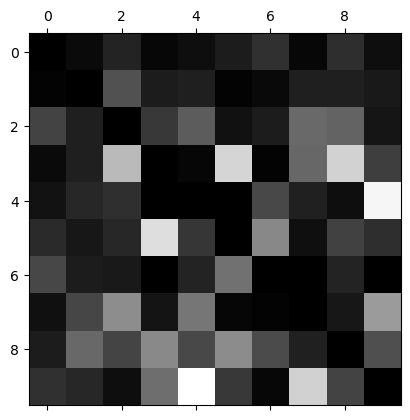

In [69]:
plt.matshow(normat,cmap = plt.cm.gray)

In [71]:
from sklearn.neighbors import KNeighborsClassifier
y_train_large = (y_train>=7)
y_train_odd = (y_train%2==1)
y_multi = np.column_stack((y_train_large,y_train_odd))

knc=KNeighborsClassifier()
knc.fit(x_train,y_multi)

KNeighborsClassifier()

In [72]:
knc.predict(some_number)

array([[False,  True]])

In [8]:
# 1. Create noise using 8-bit integers (dtype='uint8')
noisx = np.random.randint(0, 100, (len(x_train), 784), dtype='uint8')
noistestx = np.random.randint(0, 100, (len(x_test), 784), dtype='uint8')

# 2. targets are just the clean images
y_train_mod = x_train.copy()
y_test_mod = x_test.copy()

# 3. Add the noise safely
x_train_mod = x_train + noisx
x_test_mod = x_test + noistestx

# 4. Free up the raw noise arrays immediately to save RAM
del noisx, noistestx



In [10]:
from sklearn.neighbors import KNeighborsClassifier
knc=KNeighborsClassifier()
knc.fit(x_train_mod,y_train_mod)

KNeighborsClassifier()

In [16]:
x_test_mod.shape

(10000, 784)

d:\Anaconda\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


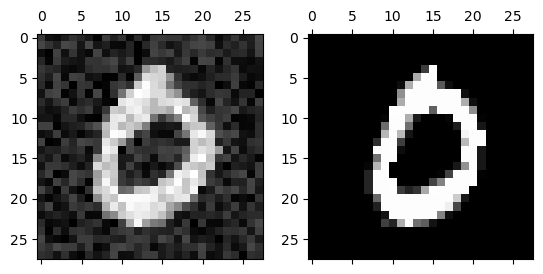

In [39]:
ans=knc.predict([x_test_mod.iloc[3,:]])
ques  = x_test_mod.iloc[3,:].values.reshape(28,28)
ans = ans.reshape(28,28)
fig,axes = plt.subplots(nrows=1,ncols=2)
axes[0].matshow(ques,cmap='gray')
axes[1].matshow(ans,cmap='gray')
